# 06 — Peak demand: how well does the model forecast each day's peak?

System operators and utilities care most about the **daily peak**: how high demand will go and at what hour. Notebook 03 reports one peak number (2.8% daily-peak MAPE). This notebook looks at the peak in detail for the 2025 test year:

- **peak MW error**: forecast daily maximum vs actual daily maximum,
- **peak hour error**: does the forecast put the peak in the right hour?
- accuracy by **season** and on the **highest-demand days**,
- the **10 worst peak days** of 2025, plotted hour by hour.

Every metric is compared with the persistence baseline (same hour yesterday). The model is rebuilt exactly as in notebooks 03–05.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb

from src.data import build_dataset
from src.features import make_features, FEATURES

warnings.filterwarnings("ignore", message=".*eval_set.*deprecated")  # newer LightGBM versions only
d = make_features(build_dataset())
train, valid, test = d.loc[:"2023"], d.loc["2024"], d.loc["2025"]
train_full = d.loc[:"2024"]

params = dict(learning_rate=0.05, num_leaves=31, subsample=0.8, subsample_freq=1,
              colsample_bytree=0.8, verbose=-1, random_state=42)
gbm = lgb.LGBMRegressor(n_estimators=3000, **params)
gbm.fit(train[FEATURES], train["demand_mw"], eval_set=[(valid[FEATURES], valid["demand_mw"])],
        callbacks=[lgb.early_stopping(100, verbose=False)])
gbm_final = lgb.LGBMRegressor(n_estimators=int(gbm.best_iteration_ * 1.1), **params)
gbm_final.fit(train_full[FEATURES], train_full["demand_mw"])

h = test[["demand_mw", "lag_24", "temp_day_mean", "is_weekend", "is_holiday"]].copy()
h["pred"] = gbm_final.predict(test[FEATURES])
print(f"2025 hourly MAPE: {((h['pred'] - h['demand_mw']).abs() / h['demand_mw']).mean() * 100:.2f}%  (same model as notebook 03)")

2025 hourly MAPE: 2.63%  (same model as notebook 03)


## Daily peak table

For each day: the actual peak (MW and hour), the forecast peak (the maximum of the 24 forecast hours, and its hour) and the same for persistence. Hours are in EST, as reported by IESO.

In [2]:
def daily_peaks(s):
    g = s.groupby(s.index.normalize())
    return pd.DataFrame({"mw": g.max(), "hour": g.idxmax().dt.hour})

act, mod, per = daily_peaks(h["demand_mw"]), daily_peaks(h["pred"]), daily_peaks(h["lag_24"])
p = pd.DataFrame({
    "peak_mw": act["mw"], "peak_hour": act["hour"],
    "fc_peak_mw": mod["mw"], "fc_peak_hour": mod["hour"],
    "persist_peak_mw": per["mw"], "persist_peak_hour": per["hour"],
})
p["err_mw"] = p["fc_peak_mw"] - p["peak_mw"]                      # > 0 = over-forecast
p["ape"] = p["err_mw"].abs() / p["peak_mw"] * 100
p["ape_persist"] = (p["persist_peak_mw"] - p["peak_mw"]).abs() / p["peak_mw"] * 100
p["hour_err"] = (p["fc_peak_hour"] - p["peak_hour"]).abs()
p["hour_err_persist"] = (p["persist_peak_hour"] - p["peak_hour"]).abs()
daily_info = h.resample("D").agg({"temp_day_mean": "first", "is_weekend": "first", "is_holiday": "first"})
p = p.join(daily_info)
p["season"] = np.select([p.index.month.isin([12, 1, 2]), p.index.month.isin([6, 7, 8])],
                        ["Winter (Dec-Feb)", "Summer (Jun-Aug)"], "Shoulder")
print(f"{len(p)} days in 2025")
p.head()

365 days in 2025


,peak_mw,peak_hour,fc_peak_mw,fc_peak_hour,persist_peak_mw,persist_peak_hour,err_mw,ape,ape_persist,hour_err,hour_err_persist,temp_day_mean,is_weekend,is_holiday,season
datetime,,,,,,,,,,,,,,,
2025-01-01,17519.0,17,17382.399486,17,17648.0,17,-136.600514,0.779728,0.736343,0,0,1.779167,0,1,Winter (Dec-Feb)
2025-01-02,19450.0,17,18751.842788,17,17519.0,17,-698.157212,3.589497,9.928021,0,0,-1.020833,0,0,Winter (Dec-Feb)
2025-01-03,19616.0,17,19590.163475,17,19450.0,17,-25.836525,0.131711,0.846248,0,0,-3.133333,0,0,Winter (Dec-Feb)
2025-01-04,19983.0,17,19113.125708,17,19616.0,17,-869.874292,4.353072,1.836561,0,0,-4.212500,1,0,Winter (Dec-Feb)
2025-01-05,20626.0,17,19539.286646,17,19983.0,17,-1086.713354,5.268658,3.117425,0,0,-3.925000,1,0,Winter (Dec-Feb)


## Overall peak accuracy, 2025

In [3]:
def summary(df):
    return pd.Series({
        "days": len(df),
        "peak MAPE model (%)": df["ape"].mean(),
        "peak MAPE persistence (%)": df["ape_persist"].mean(),
        "peak MAE model (MW)": df["err_mw"].abs().mean(),
        "peak bias model (MW)": df["err_mw"].mean(),
        "peak hour exact, model (%)": (df["hour_err"] == 0).mean() * 100,
        "peak hour within 1 h, model (%)": (df["hour_err"] <= 1).mean() * 100,
        "peak hour within 1 h, persistence (%)": (df["hour_err_persist"] <= 1).mean() * 100,
    })

overall = summary(p)
print(f"Peak under-forecast on {(p['err_mw'] < 0).mean() * 100:.0f}% of days")
print(f"Peak error within 2%: {(p['ape'] <= 2).mean() * 100:.0f}% of days; above 5%: {(p['ape'] > 5).sum()} days")
overall.round(2).to_frame("2025")

Peak under-forecast on 83% of days
Peak error within 2%: 43% of days; above 5%: 50 days


,2025
days,365.00
peak MAPE model (%),2.76
peak MAPE persistence (%),3.84
peak MAE model (MW),536.64
peak bias model (MW),-412.14
"peak hour exact, model (%)",55.34
"peak hour within 1 h, model (%)",83.84
"peak hour within 1 h, persistence (%)",76.16


## By season, and on the highest-demand days

The days that matter most for capacity are the highest-demand days of the year, so the 20 days with the highest actual peak get their own row.

In [4]:
order = ["Winter (Dec-Feb)", "Shoulder", "Summer (Jun-Aug)"]
by_season = p.groupby("season").apply(summary).loc[order]
top20 = p.nlargest(20, "peak_mw")
by_season.loc["Top 20 peak-demand days"] = summary(top20)
by_season.loc["All of 2025"] = overall
print(f"Top 20 peak days: {(top20['season'] == 'Summer (Jun-Aug)').sum()} in summer, "
      f"peaks from {top20['peak_mw'].min():,.0f} to {top20['peak_mw'].max():,.0f} MW")
print(f"Highest 2025 peak: {p['peak_mw'].max():,.0f} MW on {p['peak_mw'].idxmax().date()} "
      f"at {p.loc[p['peak_mw'].idxmax(), 'peak_hour']:02d}:00 EST, forecast {p.loc[p['peak_mw'].idxmax(), 'fc_peak_mw']:,.0f} MW")
by_season.round(2)

Top 20 peak days: 20 in summer, peaks from 22,918 to 24,862 MW
Highest 2025 peak: 24,862 MW on 2025-06-24 at 18:00 EST, forecast 24,234 MW


,days,peak MAPE model (%),peak MAPE persistence (%),peak MAE model (MW),peak bias model (MW),"peak hour exact, model (%)","peak hour within 1 h, model (%)","peak hour within 1 h, persistence (%)"
season,,,,,,,,
Winter (Dec-Feb),90.0,2.65,2.75,542.67,-515.63,76.67,96.67,93.33
Shoulder,183.0,2.29,3.65,402.19,-287.85,55.19,78.69,73.22
Summer (Jun-Aug),92.0,3.81,5.27,798.17,-558.13,34.78,81.52,65.22
Top 20 peak-demand days,20.0,4.75,3.95,1122.06,-1122.06,40.00,80.00,55.00
All of 2025,365.0,2.76,3.84,536.64,-412.14,55.34,83.84,76.16


## When does the peak happen?

Share of days whose actual peak falls in each hour, by season, against where the forecast puts it.

In [5]:
hour_tab = pd.crosstab(p["peak_hour"], p["season"], normalize="columns").mul(100)[order]
fc_hour_tab = pd.crosstab(p["fc_peak_hour"], p["season"], normalize="columns").mul(100)[order]
for s in order:
    print(f"{s:18s} most common actual peak hour {hour_tab[s].idxmax():02d}:00 ({hour_tab[s].max():.0f}% of days); "
          f"forecast {fc_hour_tab[s].idxmax():02d}:00 ({fc_hour_tab[s].max():.0f}%)")
hour_tab.round(0).loc[lambda t: t.sum(axis=1) > 0]

Winter (Dec-Feb)   most common actual peak hour 17:00 (62% of days); forecast 17:00 (71%)
Shoulder           most common actual peak hour 19:00 (26% of days); forecast 19:00 (30%)
Summer (Jun-Aug)   most common actual peak hour 17:00 (42% of days); forecast 17:00 (40%)


season,Winter (Dec-Feb),Shoulder,Summer (Jun-Aug)
peak_hour,,,
6,0.0,3.0,0.0
7,0.0,2.0,0.0
8,0.0,1.0,0.0
10,1.0,2.0,0.0
11,1.0,1.0,1.0
12,1.0,1.0,4.0
13,0.0,0.0,1.0
14,0.0,0.0,4.0
15,0.0,1.0,2.0


## The 10 worst peak days of 2025

Ranked by the absolute error on the daily peak MW.

In [6]:
worst = p.nlargest(10, "ape")
print(f"Worst 10 peak days: {(worst['err_mw'] < 0).sum()} under-forecast; {(worst['season'] == 'Summer (Jun-Aug)').sum()} in summer; "
      f"{((worst['is_weekend'] == 1) | (worst['is_holiday'] == 1)).sum()} on weekends or holidays; "
      f"{(worst['temp_day_mean'] >= 23).sum()} with a daily mean of 23 °C or more")
print(f"Mean peak error on these days: model {worst['ape'].mean():.2f}%, persistence {worst['ape_persist'].mean():.2f}%")
cols = ["peak_mw", "fc_peak_mw", "err_mw", "ape", "ape_persist", "peak_hour", "fc_peak_hour", "temp_day_mean", "season"]
worst_tab = worst[cols].assign(weekday=worst.index.day_name().str[:3])
worst_tab.round(1)

Worst 10 peak days: 9 under-forecast; 8 in summer; 5 on weekends or holidays; 5 with a daily mean of 23 °C or more
Mean peak error on these days: model 8.90%, persistence 6.25%


,peak_mw,fc_peak_mw,err_mw,ape,ape_persist,peak_hour,fc_peak_hour,temp_day_mean,season,weekday
datetime,,,,,,,,,,
2025-04-02,19492.0,17516.7,-1975.3,10.1,8.4,16,19,0.7,Shoulder,Wed
2025-07-26,21911.0,19803.1,-2107.9,9.6,5.2,14,15,23.7,Summer (Jun-Aug),Sat
2025-08-10,24063.0,21803.4,-2259.6,9.4,3.4,17,17,26.9,Summer (Jun-Aug),Sun
2025-08-18,18932.0,17220.5,-1711.5,9.0,0.9,16,17,17.8,Summer (Jun-Aug),Mon
2025-06-30,19565.0,21295.1,1730.1,8.8,4.0,12,15,22.6,Summer (Jun-Aug),Mon
2025-08-13,23843.0,21741.4,-2101.6,8.8,0.7,16,13,24.4,Summer (Jun-Aug),Wed
2025-12-26,19569.0,17884.7,-1684.3,8.6,7.9,17,17,-4.9,Winter (Dec-Feb),Fri
2025-08-09,23248.0,21304.3,-1943.7,8.4,2.6,17,16,25.9,Summer (Jun-Aug),Sat
2025-06-27,20251.0,18586.4,-1664.6,8.2,10.8,17,19,19.5,Summer (Jun-Aug),Fri


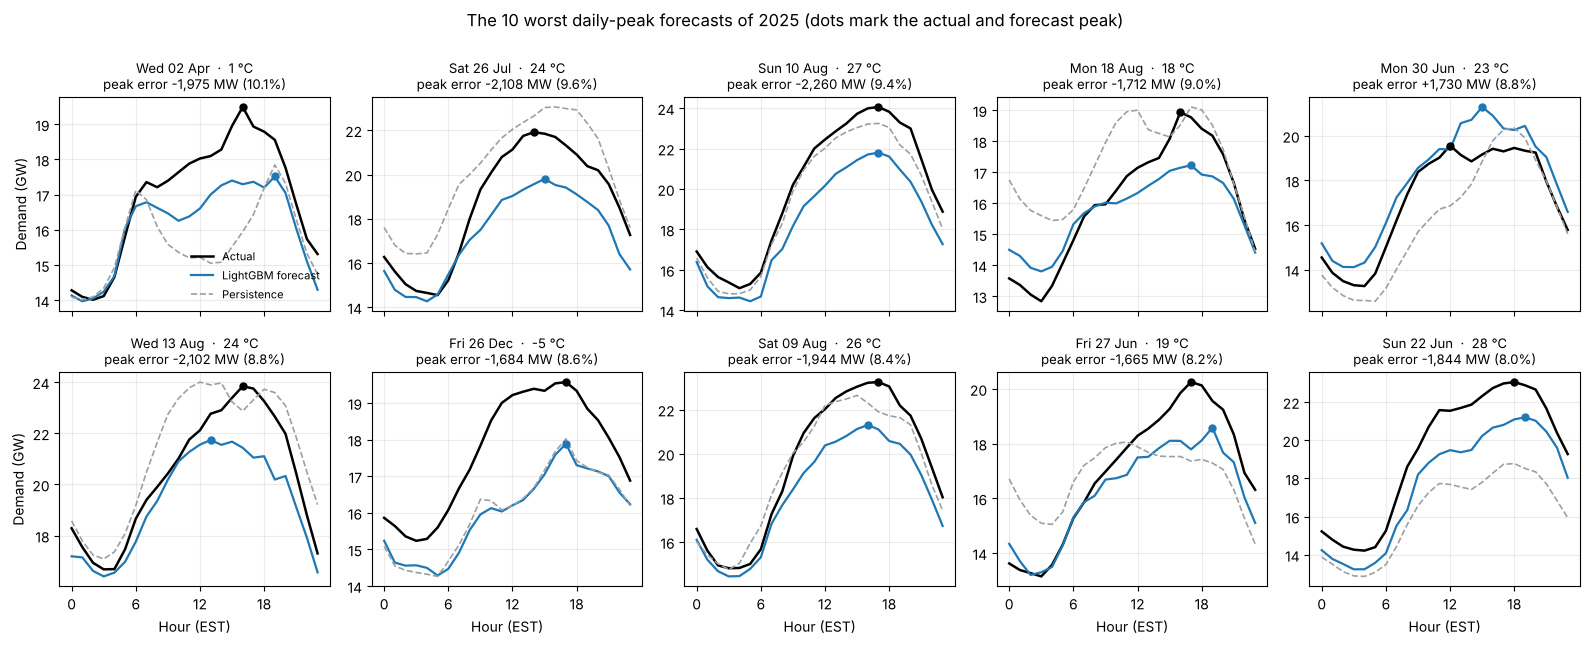

In [7]:
fig, axes = plt.subplots(2, 5, figsize=(16, 6.4), sharex=True)
for ax, (day, row) in zip(axes.flat, worst.iterrows()):
    s = h.loc[str(day.date())]
    hrs = s.index.hour
    ax.plot(hrs, s["demand_mw"] / 1000, color="black", lw=1.8, label="Actual")
    ax.plot(hrs, s["pred"] / 1000, color="#1f77b4", lw=1.6, label="LightGBM forecast")
    ax.plot(hrs, s["lag_24"] / 1000, color="#9aa0a6", lw=1.2, ls="--", label="Persistence")
    ax.plot(row["peak_hour"], row["peak_mw"] / 1000, "o", color="black", ms=5)
    ax.plot(row["fc_peak_hour"], row["fc_peak_mw"] / 1000, "o", color="#1f77b4", ms=5)
    ax.set_title(f"{day:%a %d %b}  ·  {row['temp_day_mean']:.0f} °C\npeak error {row['err_mw']:+,.0f} MW ({row['ape']:.1f}%)", fontsize=9.5)
    ax.set_xticks(range(0, 24, 6))
    ax.grid(alpha=0.25)
for ax in axes[:, 0]:
    ax.set_ylabel("Demand (GW)")
for ax in axes[1]:
    ax.set_xlabel("Hour (EST)")
axes.flat[0].legend(frameon=False, fontsize=8, loc="lower right")
fig.suptitle("The 10 worst daily-peak forecasts of 2025 (dots mark the actual and forecast peak)", y=1.0)
fig.tight_layout()
fig.savefig("figures/worst_peak_days_2025.png", dpi=130, bbox_inches="tight")
plt.show()

## Takeaways (2025 test year)

- **The model forecasts the daily peak within 2.76% on average (537 MW)**, against 3.84% for persistence. The peak error is within 2% on 43% of days and above 5% on 50 days.
- **It under-forecasts the peak on 83% of days**, by 412 MW on average. That is larger than the −295 MW bias on all hours found in notebook 05, so the 2025 load-growth under-forecast hits hardest at the peak.
- **Peak timing is good, especially in winter.** The forecast puts the peak in the exact hour on 55% of days and within one hour on 84% (persistence: 76%). Winter peaks are regular (62% of winter days peak at 17:00) and the model is within one hour on 97% of them. Summer peaks spread over 16:00–18:00: the exact hour is right on only 35% of summer days, but within one hour on 82% against 65% for persistence.
- **Summer peaks are the weak spot.** Summer peak MAPE is 3.81% (798 MW, bias −558 MW). All 20 highest-demand days of 2025 are summer days (22,918–24,862 MW). On those days the model under-forecasts every peak, by 1,122 MW on average (4.75%), and persistence does better (3.95%). The highest peak of the year, 24,862 MW on 24 June at 18:00 EST, was forecast at 24,234 MW.
- **The 10 worst peak days** are mostly hot summer days: 9 are under-forecast, 8 are in summer, 5 are weekends or holidays and 5 have a daily mean of 23 °C or more. Two are cold days: 2 April (0.7 °C), when demand stayed high through the afternoon, and Boxing Day, which the model treats as a low-demand holiday.
- **Implication:** the fixes that matter most for peaks are the load-growth bias and better hot-day features (humidex, multi-city temperature), and a P90 quantile forecast would give planners a usable upper bound on the summer peak.